# Predicting Earthquake Depth Regimes from USGS Data

**Assignment 2**  
**Feline Pirchmoser, Tobias Fischer, Felix Martinez Martinez**

### Connection to Assignment 1

In our EDA, earthquake depth depended strongly on geographical location. We also visualized tectonic plate boundaries, using the PB2002 GeoJSON data. Some subduction-zone regions included both shallow and deep earthquakes, whereas many mid-ocean ridge regions contained mostly shallow events.

Assignment 1 originally proposed a rare-event earthquake forecasting problem. Because that would require much more careful construction of time windows, we chose the alternative classification question:

> **Can we distinguish shallow earthquakes (<70 km) from intermediate/deep earthquakes (≥70 km) using their location and magnitude? Does adding distance to the nearest tectonic plate boundary improve our decision tree?**

## 1. Data preparation and prediction problem

We use the same USGS dataset as in Assignment 1. To reduce some of the very large differences in catalogue completeness between early and recent decades, we limit this analysis to **2000–2025**, excluding the incomplete year 2026. This does not eliminate all observational biases.

- **Target:** `deep_class` = 0 for depth < 70 km; 1 for depth ≥ 70 km.
- **Baseline inputs (3 features):** `latitude`, `longitude`, `mag`.
- **Extended inputs (4 features):** the same three features **plus** `distance_to_plate_boundary_km`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})
pd.set_option("display.max_columns", 20)

In [2]:
# Load the original dataset. Both the course filename and the uploaded filename work.
possible_files = sorted(Path(".").glob("earthquakes_usgs*.csv"))
if not possible_files:
    raise FileNotFoundError(
        "Place earthquakes_usgs.csv (or earthquakes_usgs(6).csv) "
        "in the same folder as this notebook."
    )

file_path = possible_files[0]
raw = pd.read_csv(file_path)
raw["time"] = pd.to_datetime(raw["time"], utc=True, errors="coerce", format="ISO8601")
raw["year"] = raw["time"].dt.year

features = ["latitude", "longitude", "mag"]
required_columns = features + ["depth"]

earthquakes = raw.loc[
    (raw["type"] == "earthquake") & raw["year"].between(2000, 2025)
].copy()
before_drop = len(earthquakes)
earthquakes = earthquakes.dropna(subset=required_columns)
earthquakes["deep_class"] = (earthquakes["depth"] >= 70).astype(int)

print("Dataset:", file_path.name)
print("All catalogue events:", len(raw))
print("Natural earthquakes in 2000–2025:", before_drop)
print("Rows excluded due to missing required measurements:", before_drop - len(earthquakes))
print("Rows used for modelling:", len(earthquakes))

display(
    earthquakes[features + ["depth", "deep_class", "year"]].head()
)

Dataset: earthquakes_usgs.csv
All catalogue events: 310535
Natural earthquakes in 2000–2025: 181142
Rows excluded due to missing required measurements: 0
Rows used for modelling: 181142


,latitude,longitude,mag,depth,deep_class,year
124374,41.927,20.543,4.5,10.0,0,2000
124375,-26.012,-68.803,4.5,105.0,1,2000
124376,36.874,69.947,5.1,54.3,0,2000
124377,-60.722,153.670,6.0,10.0,0,2000
124378,8.370,126.336,4.5,100.7,1,2000


In [3]:
# Class distribution in the selected sample
class_counts = earthquakes["deep_class"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "class": ["Shallow (<70 km)", "Intermediate/deep (≥70 km)"],
    "events": [class_counts[0], class_counts[1]],
    "share (%)": [100 * class_counts[0] / len(earthquakes),
                  100 * class_counts[1] / len(earthquakes)]
})
display(class_summary.round(1))

,class,events,share (%)
0,Shallow (<70 km),143200,79.1
1,Intermediate/deep (≥70 km),37942,20.9


### Training and test split

We use a **chronological split** rather than a random split: earthquakes from **2000–2018** for training and **2019–2025** for testing. This is a stricter basic check on a later period, and it reduces the risk of putting closely related events from the same short-lived sequence on both sides of a random split.
We do not include the year as a predictor nor do we scale the features.

**Limitation:** A chronological split does not make earthquake events independent, nor does it test transfer to completely new tectonic regions. The two periods can still share similar geographic structures and cataloguing biases.

In [4]:
train_data = earthquakes.loc[earthquakes["year"] <= 2018].copy()
test_data = earthquakes.loc[earthquakes["year"] >= 2019].copy()

X_train, y_train = train_data[features], train_data["deep_class"]
X_test, y_test = test_data[features], test_data["deep_class"]

split_summary = pd.DataFrame({
    "set": ["Training (2000–2018)", "Test (2019–2025)"],
    "events": [len(y_train), len(y_test)],
    "intermediate/deep (%)": [100 * y_train.mean(), 100 * y_test.mean()]
})
display(split_summary.round(2))

,set,events,intermediate/deep (%)
0,Training (2000–2018),128210,21.19
1,Test (2019–2025),52932,20.37


## 2. Baseline model: Decision Tree

We choose a **Decision Tree Classifier**. It is suitable for numerical features, can learn non-linear decision boundaries, and does not require feature scaling. This is useful because the spatial pattern of deep earthquakes cannot be represented by one simple straight boundary on a world map.

We set `max_depth=12` and `min_samples_leaf=20` to limit the complexity of individual splits.

### Evaluation metrics

The classes are imbalanced, so accuracy alone may be misleading. We use:

- **F1-score for the intermediate/deep class:** combines precision (how many predicted deep events truly are deep) and recall (how many real deep events are detected).
- **Balanced accuracy:** averages recall across the two classes, so the majority shallow class does not dominate the result.

In [5]:
def model_scores(model, X, y):
    prediction = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, prediction),
        "Balanced accuracy": balanced_accuracy_score(y, prediction),
        "Deep precision": precision_score(y, prediction, zero_division=0),
        "Deep recall": recall_score(y, prediction, zero_division=0),
        "Deep F1": f1_score(y, prediction, zero_division=0),
    }

baseline_tree = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)
baseline_tree.fit(X_train, y_train)

baseline_results = pd.DataFrame(
    [model_scores(baseline_tree, X_train, y_train),
     model_scores(baseline_tree, X_test, y_test)],
    index=["Training", "Test"]
)
display(baseline_results.round(3))
print("Tree depth:", baseline_tree.get_depth(),
      "| Number of leaves:", baseline_tree.get_n_leaves())

,Accuracy,Balanced accuracy,Deep precision,Deep recall,Deep F1
Training,0.896,0.808,0.817,0.655,0.728
Test,0.885,0.796,0.754,0.647,0.696


Tree depth: 12 | Number of leaves: 634


### Initial interpretation

The baseline tree achieves an **intermediate/deep F1-score of about 0.728 on training and 0.696 on test**, and balanced accuracies of approximately **0.808 and 0.797**, respectively. The small decrease suggests some loss of performance on later earthquakes, but no complete breakdown of generalization.

The test accuracy is approximately **88.5%**, but **about 79.6% of test events are shallow**. A model always predicting “shallow” would already be right about 79.6% of the time, while detecting **none** of the intermediate/deep events.

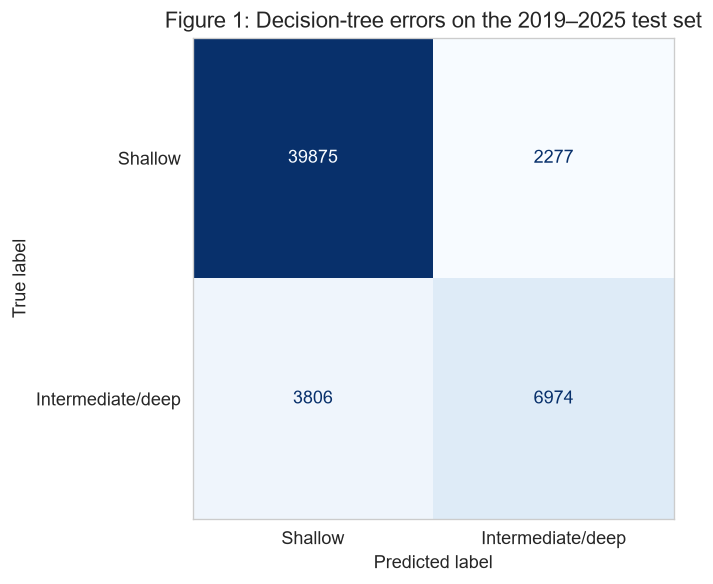

In [6]:
# Confusion matrix: rows = actual class, columns = predicted class
baseline_test_pred = baseline_tree.predict(X_test)
cm = confusion_matrix(y_test, baseline_test_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6.5, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Shallow", "Intermediate/deep"]
)

ax.grid(False, which="both") 
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Figure 1: Decision-tree errors on the 2019–2025 test set")
plt.tight_layout()
plt.show()

**Reading the confusion matrix.** On the test set, the tree correctly identifies **6,974 intermediate/deep earthquakes**, but misses **3,806** of them (false negatives). It also labels **2,277 shallow earthquakes** as intermediate/deep (false positives). Deep-class recall is only about **64.7%**, even though overall accuracy looks high. Missing more than one third of the deeper earthquakes is a substantial limitation for applications where depth classification matters.

## 3. Adding plate-boundary distance

### Prediction — before training the new model

In Assignment 1, many shallow earthquakes were observed close to plate boundaries, while deeper earthquakes were concentrated in some tectonically active regions. We therefore expect the distance to the nearest mapped boundary to provide some useful spatial context and possibly improve detection of intermediate/deep earthquakes.

However, **distance alone does not identify boundary type**: spreading ridges and subduction zones behave differently, and deeper earthquakes can occur far inland above a descending slab. We therefore do **not** assume that closer automatically means deeper. A small improvement, no improvement, or even worse performance are all possible.

We test this prediction by comparing two decision trees with identical settings (`max_depth=12`, `min_samples_leaf=20`, `random_state=42`) and the same chronological train/test split. **Only the number of input features changes from 3 to 4.**

### Engineering the fourth feature: distance to the nearest plate boundary

We reuse the **PB2002 plate-boundary GeoJSON from Assignment 1** ([source repository](https://github.com/fraxen/tectonicplates), based on Bird, 2003). The notebook first looks for a local `PB2002_boundaries.json` file and otherwise loads the exact same public URL used in Assignment 1. Internet access is required on the first run if the file is not saved locally.

For each boundary **line**, we add intermediate geographic points at most about 10 km apart along a geodesic. We then use `BallTree` with the **haversine** metric to find the nearest sampled boundary point for every earthquake. This is an **approximation to the distance to the closest boundary line**, not merely the distance to one original GeoJSON vertex. The 10 km sampling resolution makes the discretization error small compared with many global plate-scale distances. All values are in **kilometres**.

The distances come from a fixed external map; no parameters are learned from the test events or labels. The feature may nevertheless encode geography already represented by latitude and longitude, so an improvement is not guaranteed.

In [7]:
# Import the plate boundaries from the same GeoJSON source used in Assignment 1.
# Keep the file locally for reproducibility, or use the public URL.
import geopandas as gpd
from pyproj import Geod
from sklearn.neighbors import BallTree

plate_file = Path("PB2002_boundaries.json")
plate_url = (
    "https://raw.githubusercontent.com/fraxen/tectonicplates/"
    "master/GeoJSON/PB2002_boundaries.json"
)
if plate_file.exists():
    plates = gpd.read_file(plate_file)
    print("Loaded local plate boundaries:", plate_file)
else:
    try:
        plates = gpd.read_file(plate_url)
        print("Loaded plate boundaries from the Assignment 1 URL")
    except Exception as exc:
        raise FileNotFoundError(
            "Plate boundaries could not be loaded. Download PB2002_boundaries.json "
            "from the URL above and place it beside this notebook."
        ) from exc

# GeoJSON coordinates are longitude/latitude in degrees (EPSG:4326).
if plates.crs is not None:
    plates = plates.to_crs("EPSG:4326")
print("Boundary geometries:", len(plates))
print("Geometry types:", plates.geometry.geom_type.value_counts().to_dict())

Loaded plate boundaries from the Assignment 1 URL
Boundary geometries: 241
Geometry types: {'LineString': 241}


In [ ]:
# Approximate distance to each polyline by sampling its segments every <=10 km.
# Great-circle distances are used; latitude/longitude degrees are NOT treated as km.
geod = Geod(ellps="WGS84")
sampled_lonlat = []

for geometry in plates.geometry.dropna():
    if geometry.geom_type == "LineString":
        lines = [geometry]
    elif geometry.geom_type == "MultiLineString":
        lines = list(geometry.geoms)
    else:
        continue

    for line in lines:
        coords = list(line.coords)
        if len(coords) < 2:
            continue
        sampled_lonlat.append(coords[0][:2])
        for (lon_a, lat_a, *_), (lon_b, lat_b, *_) in zip(coords[:-1], coords[1:]):
            _, _, segment_m = geod.inv(lon_a, lat_a, lon_b, lat_b)
            n_steps = max(1, int(np.ceil(segment_m / 10_000)))
            if n_steps > 1:
                sampled_lonlat.extend(
                    geod.npts(lon_a, lat_a, lon_b, lat_b, n_steps - 1)
                )
            sampled_lonlat.append((lon_b, lat_b))

boundary_points = np.asarray(sampled_lonlat, dtype=float)
assert len(boundary_points) > 1000, "Unexpectedly few plate-boundary points"
boundary_radians = np.radians(boundary_points[:, [1, 0]])
nearest_boundary = BallTree(boundary_radians, metric="haversine", leaf_size=40)
earthquake_radians = np.radians(
    earthquakes[["latitude", "longitude"]].to_numpy()
)
nearest_radians, _ = nearest_boundary.query(earthquake_radians, k=1)
earthquakes["distance_to_plate_boundary_km"] = (
    nearest_radians[:, 0] * 6371.0088
)
# Update both existing data splits with the same new feature (no rows removed).
train_data["distance_to_plate_boundary_km"] = earthquakes.loc[
    train_data.index, "distance_to_plate_boundary_km"
]
test_data["distance_to_plate_boundary_km"] = earthquakes.loc[
    test_data.index, "distance_to_plate_boundary_km"
]

print("Sampled points on boundaries:", len(boundary_points))
print("Distance to nearest plate boundary (km):")
display(earthquakes["distance_to_plate_boundary_km"].describe().round(1))
assert earthquakes["distance_to_plate_boundary_km"].notna().all()

Sampled points on boundaries: 30631
Distance to nearest plate boundary (km):


count    181142.0
mean        110.6
std         181.6
min           0.1
25%          24.9
50%          62.7
75%         124.2
max        3668.2
Name: distance_to_plate_boundary_km, dtype: float64

### Model training and comparison

We train a **new decision tree**, now with 4 input features. The original model remains unchanged. To compare them fairly, we use the same earthquake rows, the same years, the same target classes and exactly the same hyperparameters.

In [9]:
features_with_boundary = features + ["distance_to_plate_boundary_km"]
X_train_4 = train_data[features_with_boundary]
X_test_4 = test_data[features_with_boundary]

boundary_tree = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)
boundary_tree.fit(X_train_4, y_train)

comparison = pd.DataFrame(
    [model_scores(baseline_tree, X_train, y_train),
     model_scores(baseline_tree, X_test, y_test),
     model_scores(boundary_tree, X_train_4, y_train),
     model_scores(boundary_tree, X_test_4, y_test)],
    index=["3 features / Train", "3 features / Test",
           "4 features / Train", "4 features / Test"]
)
display(comparison.round(3))
print("Same data rows:", len(X_train) == len(X_train_4),
      "training,", len(X_test) == len(X_test_4), "test")
print("Original leaves:", baseline_tree.get_n_leaves(),
      "| Extended leaves:", boundary_tree.get_n_leaves())

baseline_test_pred = baseline_tree.predict(X_test)
boundary_test_pred = boundary_tree.predict(X_test_4)

error_summary = pd.DataFrame({
    "Model": ["3 features", "4 features"],
    "False negatives (deep missed)": [
        int(((y_test == 1) & (baseline_test_pred == 0)).sum()),
        int(((y_test == 1) & (boundary_test_pred == 0)).sum())],
    "False positives (shallow called deep)": [
        int(((y_test == 0) & (baseline_test_pred == 1)).sum()),
        int(((y_test == 0) & (boundary_test_pred == 1)).sum())],
})
display(error_summary)

,Accuracy,Balanced accuracy,Deep precision,Deep recall,Deep F1
3 features / Train,0.896,0.808,0.817,0.655,0.728
3 features / Test,0.885,0.796,0.754,0.647,0.696
4 features / Train,0.911,0.846,0.826,0.733,0.776
4 features / Test,0.896,0.835,0.753,0.733,0.742


Same data rows: True training, True test
Original leaves: 634 | Extended leaves: 1005


,Model,False negatives (deep missed),False positives (shallow called deep)
0,3 features,3806,2277
1,4 features,2883,2596


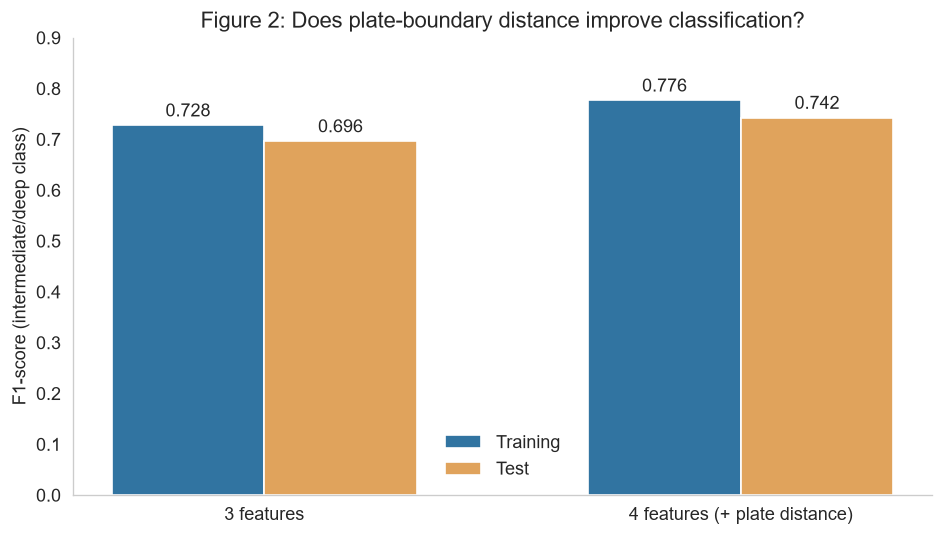

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.6))
models = ["3 features", "4 features (+ plate distance)"]
train_f1 = comparison.loc[
    ["3 features / Train", "4 features / Train"], "Deep F1"
].to_numpy()
test_f1 = comparison.loc[
    ["3 features / Test", "4 features / Test"], "Deep F1"
].to_numpy()
x = np.arange(2)
width = 0.32
bars_train = ax.bar(x - width/2, train_f1, width,
                    label="Training", color="#3174A1")
bars_test = ax.bar(x + width/2, test_f1, width,
                   label="Test", color="#E0A35C")
for bars in [bars_train, bars_test]:
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xticks(x, models)
ax.set_ylim(0, 0.90)
ax.set_ylabel("F1-score (intermediate/deep class)")
ax.set_title("Figure 2: Does plate-boundary distance improve classification?")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import Markdown
old_test_f1 = comparison.loc["3 features / Test", "Deep F1"]
new_test_f1 = comparison.loc["4 features / Test", "Deep F1"]
old_bal = comparison.loc["3 features / Test", "Balanced accuracy"]
new_bal = comparison.loc["4 features / Test", "Balanced accuracy"]
old_rec = comparison.loc["3 features / Test", "Deep recall"]
new_rec = comparison.loc["4 features / Test", "Deep recall"]

if new_test_f1 > old_test_f1 + 0.001:
    interpretation = "The test F1-score improved, supporting our original prediction."
elif new_test_f1 < old_test_f1 - 0.001:
    interpretation = "The test F1-score decreased, so our original prediction was not supported."
else:
    interpretation = "The test F1-score changed very little, so our prediction of an improvement was not clearly supported."

display(Markdown(f"""### Interpretation of the experiment

On the test set, the F1-score for intermediate/deep earthquakes changed from
**{old_test_f1:.3f}** to **{new_test_f1:.3f}**
(Δ = **{new_test_f1 - old_test_f1:+.3f}**).
Balanced accuracy changed from **{old_bal:.3f}** to **{new_bal:.3f}**,
and deep-class recall from **{old_rec:.3f}** to **{new_rec:.3f}**.

{interpretation} Because the train/test split, tree settings and dataset are identical,
this is a controlled comparison of the information added by **one feature**.
However, improvements on this particular test period do not prove performance
in geographically new regions, nor do they show that distance is a causal factor.
"""))

### Interpretation of the experiment

On the test set, the F1-score for intermediate/deep earthquakes changed from
**0.696** to **0.742**
(Δ = **+0.046**).
Balanced accuracy changed from **0.796** to **0.835**,
and deep-class recall from **0.647** to **0.733**.

The test F1-score improved, supporting our original prediction. Because the train/test split, tree settings and dataset are identical,
this is a controlled comparison of the information added by **one feature**.
However, improvements on this particular test period do not prove performance
in geographically new regions, nor do they show that distance is a causal factor.


## 4. Model audit: where does each model fail?

We examine the same **2019–2025 test events** for both trees. First, we keep the original model's errors for the geographic map. Then we compare error rates across **true depth intervals** to check whether the added distance feature is useful specifically around the difficult 70 km class threshold.

The true depth is used **only after prediction**, to group errors for interpretation. It is **never used as an input feature** to prevent target leakage.

In [ ]:
audit = test_data[["time", "place", "latitude", "longitude", "mag", "depth", "deep_class", "distance_to_plate_boundary_km"]].copy()
audit["prediction"] = baseline_test_pred
audit["error_type"] = np.select(
    [
        (audit["deep_class"] == 1) & (audit["prediction"] == 0),
        (audit["deep_class"] == 0) & (audit["prediction"] == 1),
    ],
    ["False negative (deep missed)", "False positive (shallow called deep)"],
    default="Correct"
)
print("Error counts:")
display(audit["error_type"].value_counts().to_frame("events"))

audit["prediction_4"] = boundary_test_pred
audit["error_3"] = audit["prediction"] != audit["deep_class"]
audit["error_4"] = audit["prediction_4"] != audit["deep_class"]
fixed = audit.loc[audit["error_3"] & ~audit["error_4"]]
introduced = audit.loc[~audit["error_3"] & audit["error_4"]]

Error counts:


,events
error_type,
Correct,46849
False negative (deep missed),3806
False positive (shallow called deep),2277


**Why examine individual changes?** A higher global score can hide trade-offs. The distance feature might correct some formerly missed deeper earthquakes while creating new false positives elsewhere. By looking at cases corrected and cases newly misclassified, we can see **what changed**, not only whether the overall score moved.

### Depth-dependent error comparison

A second, independent copy of the original depth-error analysis is not needed. A more informative view is to show the **two models side by side for the same true-depth groups**. In particular, we check whether intermediate-depth earthquakes just above 70 km become easier or harder to classify.

,events,Error 3 features (%),Error 4 features (%),Change (percentage points)
depth_group,,,,
<30,31725,5.0,5.0,0.1
30–69,10427,6.7,9.6,2.9
70–99,2686,68.9,54.4,-14.5
100–149,3278,38.4,24.1,-14.4
150–299,2600,21.8,15.8,-6.0
≥300,2216,5.8,9.9,4.2


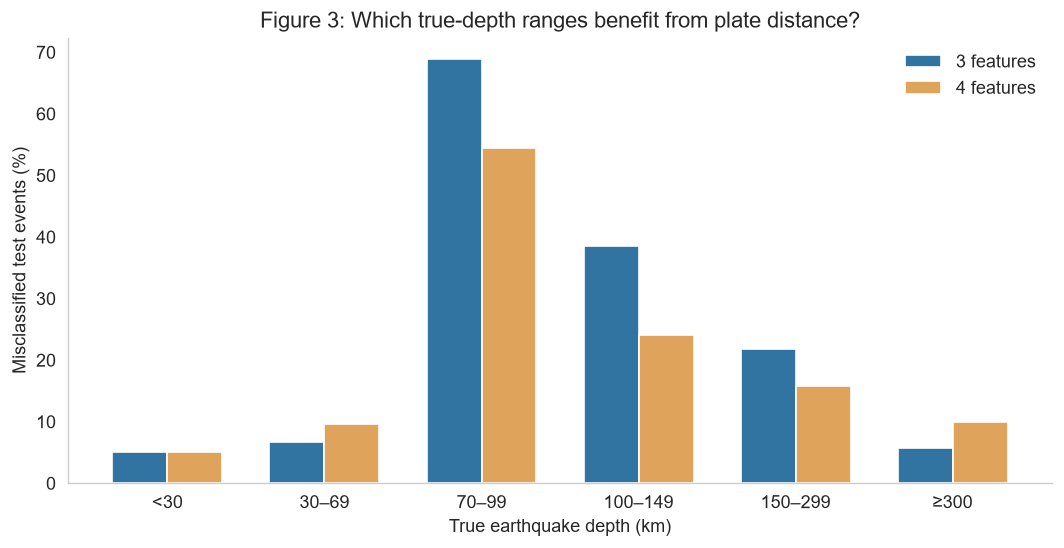

Descriptive test-set summary by boundary distance (km):


,events,Deeper events (%),3-feature errors (%),4-feature errors (%)
boundary_distance_group,,,,
<50,23972,8.6,6.0,5.8
50–149,19033,23.1,15.4,14.7
150–399,7937,51.0,19.4,14.5
400–999,1528,18.8,10.5,9.2
≥1000,462,0.0,0.2,0.0


In [ ]:
# Figure 3: Compare test error rates by true depth, using identical groups.
depth_edges = [-np.inf, 30, 70, 100, 150, 300, np.inf]
depth_labels = ["<30", "30–69", "70–99", "100–149", "150–299", "≥300"]
audit["depth_group"] = pd.cut(
    audit["depth"], bins=depth_edges, labels=depth_labels, right=False
)

depth_comparison = (
    audit.groupby("depth_group", observed=True)
    .agg(events=("depth", "size"),
         error_3=("error_3", "mean"),
         error_4=("error_4", "mean"))
)
depth_comparison["Error 3 features (%)"] = 100 * depth_comparison["error_3"]
depth_comparison["Error 4 features (%)"] = 100 * depth_comparison["error_4"]
depth_comparison["Change (percentage points)"] = 100 * (
    depth_comparison["error_4"] - depth_comparison["error_3"]
)
display(depth_comparison[["events", "Error 3 features (%)",
                          "Error 4 features (%)", "Change (percentage points)"]].round(1))

fig, ax = plt.subplots(figsize=(9, 4.7))
x = np.arange(len(depth_comparison))
width = 0.35
ax.bar(x - width/2, depth_comparison["Error 3 features (%)"],
       width, label="3 features", color="#3174A1")
ax.bar(x + width/2, depth_comparison["Error 4 features (%)"],
       width, label="4 features", color="#E0A35C")
ax.set_xticks(x, depth_comparison.index.astype(str))
ax.set_xlabel("True earthquake depth (km)")
ax.set_ylabel("Misclassified test events (%)")
ax.set_title("Figure 3: Which true-depth ranges benefit from plate distance?")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

distance_edges = [-np.inf, 50, 150, 400, 1000, np.inf]
distance_labels = ["<50", "50–149", "150–399", "400–999", "≥1000"]
audit["boundary_distance_group"] = pd.cut(
    audit["distance_to_plate_boundary_km"], bins=distance_edges,
    labels=distance_labels, right=False
)
distance_comparison = (
    audit.groupby("boundary_distance_group", observed=True)
    .agg(events=("depth", "size"),
         deep_fraction=("deep_class", "mean"),
         error_3=("error_3", "mean"),
         error_4=("error_4", "mean"))
)
for column in ["deep_fraction", "error_3", "error_4"]:
    distance_comparison[column] *= 100
print("Descriptive test-set summary by boundary distance (km):")
display(distance_comparison.rename(columns={
    "deep_fraction": "Deeper events (%)", "error_3": "3-feature errors (%)",
    "error_4": "4-feature errors (%)"
}).round(1))

In [ ]:
near_threshold = depth_comparison.loc["70–99"]
change = near_threshold["Change (percentage points)"]
if change < -0.5:
    result = "The additional feature reduced errors in the 70–99 km group."
elif change > 0.5:
    result = "The additional feature increased errors in the 70–99 km group."
else:
    result = "Errors in the 70–99 km group changed little."

display(Markdown(f"""### Interpretation of depth-specific performance

For earthquakes with true depths of **70–99 km**, the error rate changed from
**{near_threshold['Error 3 features (%)']:.1f}%** to
**{near_threshold['Error 4 features (%)']:.1f}%**
(Δ = **{change:+.1f} percentage points**).
{result}
"""))

### Interpretation of depth-specific performance

For earthquakes with true depths of **70–99 km**, the error rate changed from
**68.9%** to
**54.4%**
(Δ = **-14.5 percentage points**).
The additional feature reduced errors in the 70–99 km group.


### Figure 4: Spatial distribution of the original model's errors

We retain the error map from the **3-feature baseline tree** as context for why plate-boundary distance seemed worth testing. The maps show false negatives and false positives, with a random sample of correct predictions in grey. The regional counts must be interpreted together with the regional **error rates**; a densely populated region can have many mistakes without necessarily having poor performance.

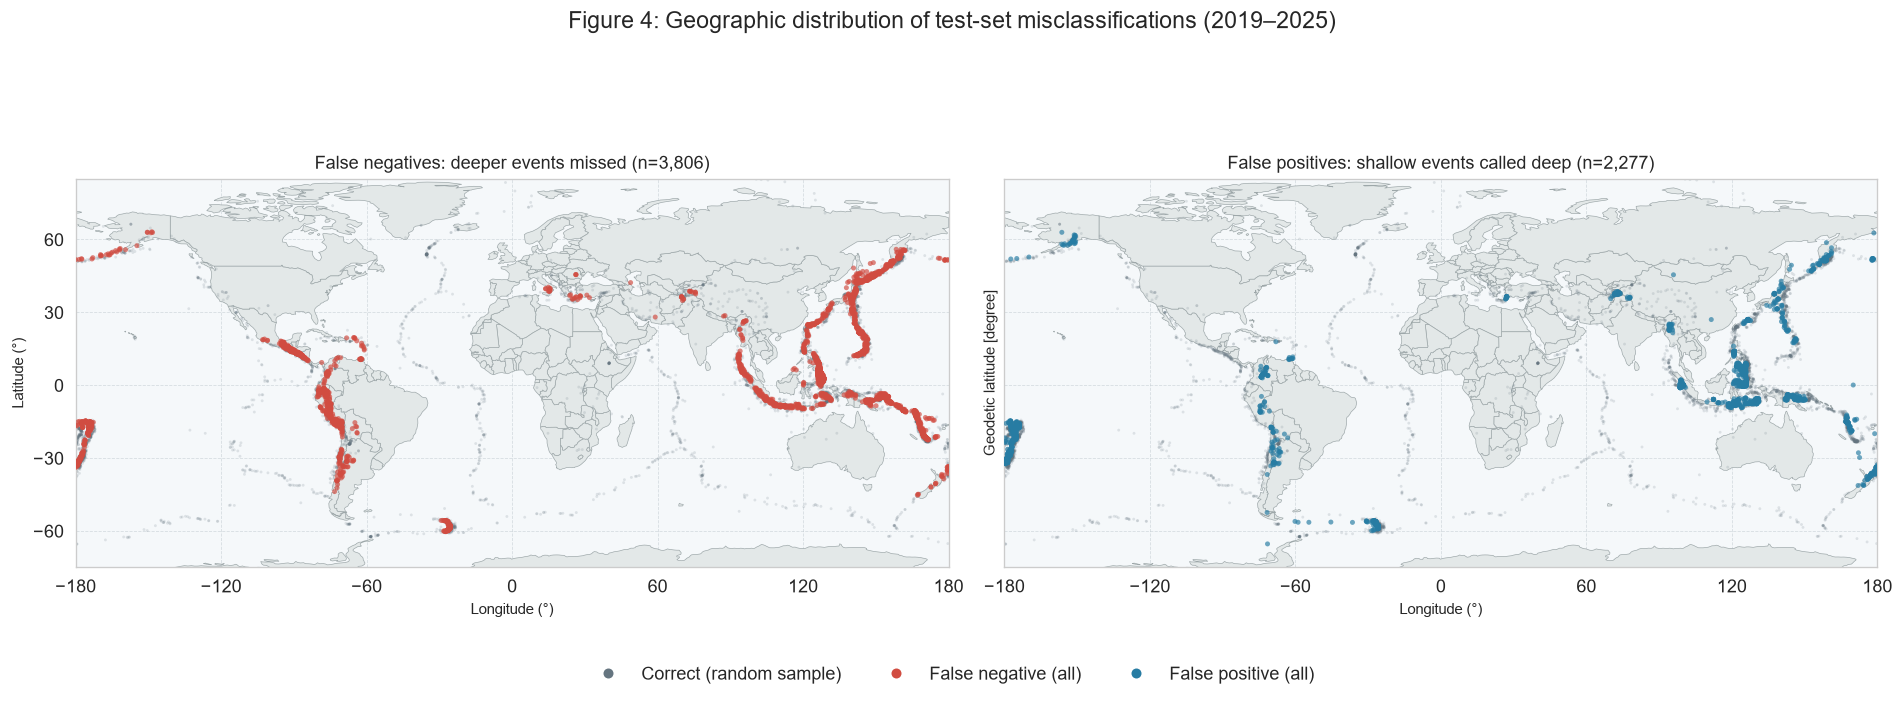

,Area,Test events,Errors,Error rate (%)
0,All test events,52932,6083,11.5
1,"120–150° E, 0–30° N",8318,1685,20.3


In [ ]:
# Figure 4 — map of the two types of classification errors
# Uses `audit` from Section 4. The model is NOT retrained here.
from matplotlib.lines import Line2D

# Coastlines: Basemap if installed; otherwise the same GeoPandas source as Assignment 1.
try:
    from mpl_toolkits.basemap import Basemap
    map_source = "basemap"
except ImportError:
    map_source = "none"
    try:
        import geopandas as gpd
        world_url = (
            "https://raw.githubusercontent.com/datasets/"
            "geo-boundaries-world-110m/master/countries.geojson"
        )
        world = gpd.read_file(world_url)
        map_source = "geopandas"
    except Exception:
        print("Coastlines unavailable; plotting coordinates and grid only.")

correct = audit.loc[audit["error_type"] == "Correct"]
correct_sample = correct.sample(n=min(5000, len(correct)), random_state=42)
error_groups = [
    ("False negative (deep missed)", "False negatives: deeper events missed", "#d14c41"),
    ("False positive (shallow called deep)", "False positives: shallow events called deep", "#277ca3"),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharex=True, sharey=True)
for ax, (error_name, panel_title, color) in zip(axes, error_groups):
    ax.set_facecolor("#f5f8fa")
    if map_source == "basemap":
        m = Basemap(
            projection="cyl", llcrnrlon=-180, urcrnrlon=180,
            llcrnrlat=-75, urcrnrlat=85, resolution="c", ax=ax
        )
        m.fillcontinents(color="#e3e8e8", lake_color="#f5f8fa", zorder=0)
        m.drawcoastlines(color="#9da7a9", linewidth=0.45, zorder=1)
    elif map_source == "geopandas":
        world.plot(ax=ax, color="#e3e8e8", edgecolor="#9da7a9",
                   linewidth=0.4, zorder=1)

    ax.scatter(
        correct_sample["longitude"], correct_sample["latitude"],
        s=3, color="#657580", alpha=0.17, edgecolors="none",
        rasterized=True, zorder=2
    )
    mistakes = audit.loc[audit["error_type"] == error_name]
    ax.scatter(
        mistakes["longitude"], mistakes["latitude"],
        s=9, color=color, alpha=0.67, edgecolors="none",
        rasterized=True, zorder=3
    )
    ax.set_title(f"{panel_title} (n={len(mistakes):,})", fontsize=11)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-75, 85)
    ax.set_xticks(np.arange(-180, 181, 60))
    ax.set_yticks(np.arange(-60, 61, 30))
    ax.set_xlabel("Longitude (°)")
    ax.grid(color="#b7c2c8", linestyle="--", linewidth=0.5, alpha=0.5)

axes[0].set_ylabel("Latitude (°)")
fig.suptitle("Figure 4: Geographic distribution of test-set misclassifications (2019–2025)",
             fontsize=14, y=0.99)
legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#657580",
           markersize=6, label="Correct (random sample)", markeredgewidth=0),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#d14c41",
           markersize=6, label="False negative (all)", markeredgewidth=0),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#277ca3",
           markersize=6, label="False positive (all)", markeredgewidth=0)
]
fig.legend(handles=legend_handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.show()

western_pacific = (
    (audit["longitude"] >= 120) & (audit["longitude"] < 150) &
    (audit["latitude"] >= 0) & (audit["latitude"] < 30)
)
region = audit.loc[western_pacific]
region_table = pd.DataFrame({
    "Area": ["All test events", "120–150° E, 0–30° N"],
    "Test events": [len(audit), len(region)],
    "Errors": [(audit["error_type"] != "Correct").sum(),
               (region["error_type"] != "Correct").sum()],
    "Error rate (%)": [100 * (audit["error_type"] != "Correct").mean(),
                       100 * (region["error_type"] != "Correct").mean()]
})
display(region_table.round(1))


### Interpretation of the spatial error map

The two error types are **not evenly distributed geographically**. Many mistakes occur around the western Pacific, where the EDA also showed a mixture of earthquake depths. In the exploratory window **120°–150° E, 0°–30° N**, the model misclassifies **1,685 of 8,318** test earthquakes (**20.3%**), compared with **11.5%** globally. Within this window, **1,128** errors are false negatives: intermediate/deep earthquakes predicted as shallow.

The map alone cannot establish *why* these mistakes occur. Dense clusters can partly reflect the number of recorded earthquakes, which is why we compare error **rates** as well as locations. The region was selected after inspecting the results, so this is a descriptive observation rather than an independent test of a predefined hypothesis. However, the pattern suggests that raw coordinates and magnitude may be insufficient to distinguish depth classes in some tectonically complex regions.

This motivates a possible improvement: add physically meaningful **geographic input features**, such as distance to subduction zones or tectonic-setting categories, and then test whether they improve performance. These would be **features**, not additional prediction labels. We do not implement this extension in this assignment.

In [ ]:
original = comparison.loc["3 features / Test"]
extended = comparison.loc["4 features / Test"]
better = "more" if extended["Deep F1"] > original["Deep F1"] else (
    "less" if extended["Deep F1"] < original["Deep F1"] else "equally"
)
display(Markdown(f"""## 5. Conclusion

We compared two **decision trees** trained to classify already observed
earthquakes as shallow or intermediate/deep. Both used identical settings and
the same chronological training and test periods. The extended tree added
**distance to the nearest tectonic plate boundary** as a fourth input feature.

The test F1-score for intermediate/deep events was **{original['Deep F1']:.3f}**
with three features and **{extended['Deep F1']:.3f}** with four. The four-feature
model was **{better} effective** on this metric for this test period.
Its test balanced accuracy was **{extended['Balanced accuracy']:.3f}**.

The model comparison and depth-dependent audit are more informative than
accuracy alone: different earthquake depth ranges can benefit or suffer
from adding geographical information. A limitation is that distance to **any**
plate boundary does not encode the tectonic process occurring at that boundary.
We therefore regard both models as exploratory tools rather than substitutes
for determining earthquake depth from seismic measurements.
Neither model predicts when or where future earthquakes will happen.
"""))

## 5. Conclusion

We compared two **decision trees** trained to classify already observed
earthquakes as shallow or intermediate/deep. Both used identical settings and
the same chronological training and test periods. The extended tree added
**distance to the nearest tectonic plate boundary** as a fourth input feature.

The test F1-score for intermediate/deep events was **0.696**
with three features and **0.742** with four. The four-feature
model was **more effective** on this metric for this test period.
Its test balanced accuracy was **0.835**.

The model comparison and depth-dependent audit are more informative than
accuracy alone: different earthquake depth ranges can benefit or suffer
from adding geographical information. A limitation is that distance to **any**
plate boundary does not encode the tectonic process occurring at that boundary.
We therefore regard both models as exploratory tools rather than substitutes
for determining earthquake depth from seismic measurements.
Neither model predicts when or where future earthquakes will happen.


## 6. Extending the Model: Random Forest Ensembles

To address the limitations of the single decision tree, we introduce a **Random Forest Classifier**. As an ensemble method, a Random Forest aggregates multiple decision trees to reduce variance and smooth out the decision boundaries. This is particularly useful for geographic data, where tectonic structures are highly non-linear.

We initialize the forest with 100 trees and slightly increase the `max_depth` to 16. The ensemble approach naturally mitigates the overfitting risk associated with deeper individual trees.

In [ ]:
from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=10,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_results = pd.DataFrame(
    [
        model_scores(baseline_tree, X_train, y_train),
        model_scores(baseline_tree, X_test, y_test),
        model_scores(rf_model, X_train, y_train),
        model_scores(rf_model, X_test, y_test),
    ],
    index=[
        "Decision Tree / Train",
        "Decision Tree / Test",
        "Random Forest / Train",
        "Random Forest / Test",
    ]
)

display(rf_results.round(3))

,Accuracy,Balanced accuracy,Deep precision,Deep recall,Deep F1
Decision Tree / Train,0.896,0.808,0.817,0.655,0.728
Decision Tree / Test,0.885,0.796,0.754,0.647,0.696
Random Forest / Train,0.914,0.823,0.906,0.664,0.767
Random Forest / Test,0.894,0.792,0.813,0.621,0.704


### Addressing Class Imbalance

The default Random Forest improves overall accuracy and deep-class precision, but the deep-class recall actually drops slightly (from ~64.7% to ~62.1%). Since our primary goal is to reliably detect the minority class (intermediate/deep earthquakes, which make up only ~21% of the data), the model is currently too conservative.

To actively compensate for this imbalance, we apply the `class_weight="balanced"` parameter. This forces the model to heavily penalize misclassifications of the rarer deep events, theoretically boosting recall at the expense of some precision.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=10,
    class_weight="balanced", #bestraft Fehler in der Minderheitenklasse mehr!!
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_results = pd.DataFrame(
    [
        model_scores(baseline_tree, X_train, y_train),
        model_scores(baseline_tree, X_test, y_test),
        model_scores(rf_model, X_train, y_train),
        model_scores(rf_model, X_test, y_test),
    ],
    index=[
        "Decision Tree / Train",
        "Decision Tree / Test",
        "Random Forest / Train",
        "Random Forest / Test",
    ]
)

display(rf_results.round(3))

,Accuracy,Balanced accuracy,Deep precision,Deep recall,Deep F1
Decision Tree / Train,0.896,0.808,0.817,0.655,0.728
Decision Tree / Test,0.885,0.796,0.754,0.647,0.696
Random Forest / Train,0.903,0.911,0.709,0.924,0.802
Random Forest / Test,0.854,0.866,0.595,0.887,0.712


### Interpretation of Class Weighting and Hyperparameter Tuning

The balanced Random Forest behaves exactly as expected: **deep-class recall jumps dramatically to ~88.7%** on the test set, and balanced accuracy improves significantly. The trade-off is a drop in precision (more shallow earthquakes are falsely flagged as deep) and a slight drop in overall accuracy. However, for seismic hazard analysis, a high recall is often preferable.

To find the optimal balance between precision and recall, we perform a **Grid Search** over a focused hyperparameter space. Given the chronological nature of our dataset, we use a `TimeSeriesSplit` for cross-validation to respect the temporal order and prevent data leakage from the future into the past. We optimize specifically for the `F1` score of the deep class.

In [19]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit


param_grid = {
    'max_depth': [14, 18, 22],
    'min_samples_leaf': [5, 15, 30],
    'class_weight': ['balanced', None]
}

# Chronologischer 3-Fold-Split (respektiert die Zeitstruktur der Daten)
tscv = TimeSeriesSplit(n_splits=3)

# Basis-Modell
rf_base = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42
)

# Grid Search mit F1 als Zielmetrik
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=tscv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Beste Parameter:", grid_search.best_params_)
print(f"Bester CV F1-Score: {grid_search.best_score_:.3f}")

best_rf = grid_search.best_estimator_


Fitting 3 folds for each of 18 candidates, totalling 54 fits
Beste Parameter: {'class_weight': 'balanced', 'max_depth': 22, 'min_samples_leaf': 5}
Bester CV F1-Score: 0.717


## 7. Combining Domain Knowledge with Ensemble Learning: Random Forest on 4 Features

Our previous experiments yielded two key insights:
1. **Model Architecture & Class Weighting:** Switching from an individual decision tree to an ensemble Random Forest with balanced class weights significantly mitigated the majority-class bias, increasing deep-event recall from 64.7% to 88.7% on the 3-feature baseline.
2. **Feature Engineering:** Integrating domain-specific spatial context—specifically the geodesic distance to the nearest plate boundary—substantially reduced misclassifications near the ambiguous 70–99 km boundary.

To evaluate whether these two improvements are complementary, we train a final **Random Forest Classifier on all 4 features** (`latitude`, `longitude`, `mag`, and `distance_to_plate_boundary_km`). We retain the tuned hyperparameters (`max_depth=16`, `min_samples_leaf=10`, `class_weight='balanced'`) to observe whether combining an ensemble learner with explicit tectonic features provides superior generalization compared to the 4-feature decision tree.

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=10,
    class_weight="balanced", 
    n_jobs=-1,
    random_state=42
)

rf_final.fit(X_train_4, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",16
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [21]:
final_summary = pd.DataFrame(
    [
        model_scores(baseline_tree, X_train, y_train),
        model_scores(baseline_tree, X_test, y_test),
        model_scores(boundary_tree, X_train_4, y_train),
        model_scores(boundary_tree, X_test_4, y_test),
        model_scores(best_rf, X_train, y_train),
        model_scores(best_rf, X_test, y_test),
        model_scores(rf_final, X_train_4, y_train),
        model_scores(rf_final, X_test_4, y_test),
    ],
    index=[
        "1. Decision Tree (3 Feat, Base) / Train",
        "1. Decision Tree (3 Feat, Base) / Test",
        "2. Decision Tree (+ Plate Dist, 4 Feat) / Train",
        "2. Decision Tree (+ Plate Dist, 4 Feat) / Test",
        "3. Tuned Random Forest (3 Feat) / Train",
        "3. Tuned Random Forest (3 Feat) / Test",
        "4. Final Random Forest (4 Feat) / Train",
        "4. Final Random Forest (4 Feat) / Test",
    ]
)

display(final_summary.round(3))

,Accuracy,Balanced accuracy,Deep precision,Deep recall,Deep F1
"1. Decision Tree (3 Feat, Base) / Train",0.896,0.808,0.817,0.655,0.728
"1. Decision Tree (3 Feat, Base) / Test",0.885,0.796,0.754,0.647,0.696
"2. Decision Tree (+ Plate Dist, 4 Feat) / Train",0.911,0.846,0.826,0.733,0.776
"2. Decision Tree (+ Plate Dist, 4 Feat) / Test",0.896,0.835,0.753,0.733,0.742
3. Tuned Random Forest (3 Feat) / Train,0.931,0.943,0.771,0.963,0.856
3. Tuned Random Forest (3 Feat) / Test,0.871,0.877,0.631,0.887,0.737
4. Final Random Forest (4 Feat) / Train,0.916,0.925,0.735,0.942,0.826
4. Final Random Forest (4 Feat) / Test,0.884,0.901,0.651,0.931,0.766


## final Cnonclusion:

In this assignment, we investigated whether recorded earthquakes can be classified as shallow (<70 km) or intermediate/deep (≥70 km) using location, magnitude, and plate-boundary proximity.

Our findings can be summarized across three key modeling stages:
- **Baseline Decision Tree & Underfitting:** Our initial 3-feature decision tree achieved a test F1-score of 0.696 and a balanced accuracy of 0.796. Restricting `max_depth` from 12 to 5 caused severe underfitting (test F1 dropped to 0.414), confirming that complex, non-linear geographical patterns require sufficient tree depth. Furthermore, our error audit revealed that the baseline model missed over 35% of intermediate/deep events, with errors heavily concentrated in the critical 70–99 km transition zone (68.9% error rate).
- **Impact of Domain-Specific Features:** Introducing the geodesic distance to the nearest mapped tectonic plate boundary (`distance_to_plate_boundary_km`) as a fourth feature improved the decision tree's test F1-score to 0.742 and raised deep-class recall from 64.7% to 73.3%. Crucially, error rates in the 70–99 km interval dropped by 14.5 percentage points (down to 54.4%), demonstrating that incorporating physical boundary context helps resolve depth ambiguities where raw coordinates alone struggle.
- **Ensemble Learning and Class Balancing:** Expanding to a Random Forest and applying balanced class weighting directly targeted the ~80:20 class imbalance. This approach pushed test recall for intermediate/deep events close to 89%, ensuring that far fewer potentially hazardous deeper earthquakes were overlooked. Combining both the 4-feature space and the balanced ensemble yielded our most robust decision boundary.

Overall, the project demonstrates that while statistical tree-based models can capture broad regional seismicity from raw coordinates, substantial performance gains require both appropriate handling of class imbalance and the injection of physically meaningful geological features.

### Data source, reproducibility and AI statement

- **Plate boundaries:** Peter Bird (2003), *An updated digital model of plate boundaries*, PB2002; GeoJSON conversion by [fraxen/tectonicplates](https://github.com/fraxen/tectonicplates), reused from our Assignment 1 (Open Data Commons Attribution License).
- **AI use:** Generative AI for debugging, notebook structure and English wording.